# Commentary Pipeline Sandbox

In [ ]:
%pip install numpy<2
%pip install seaborn
%pip install networkx
%pip install matplotlib

In [ ]:
import pandas as pd
import seaborn as seaboo
import commentary_wizard as comm_wiz
from lxml import etree 

files = ["02/sec00009.sec002.perseus-eng1","03/sec00009.sec003.perseus-eng1","04/sec00009.sec004.perseus-eng1" ,"05/sec00009.sec005.perseus-eng1", "06/sec00009.sec006.perseus-eng1","07/sec00009.sec007.perseus-eng1","08/sec00009.sec008.perseus-eng1","09/sec00009.sec009.perseus-eng1","10/sec00009.sec010.perseus-eng1"] # do this through 10
docs = [comm_wiz.parse_doc("/home/ovenmitts/git/canonical_pdlrefwk/data/sec00009/sec0" +f+".xml") for f in files]
milestones = []
textparts = []

# URN extraction. where you left off
for d in docs:
    milestone_list = [urny.get("n") for urny in d.findall(".//{http://www.tei-c.org/ns/1.0}milestone")]
    raw_textpart_list = [urny for urny in d.findall(".//{http://www.tei-c.org/ns/1.0}div") if urny.get("type") =='textpart']
    textpart_list = comm_wiz.sort_textparts(raw_textpart_list)
    #if len([m for m in milestone_list if "." not in m]) > 0:
    milestones.append(milestone_list)
    textparts.append(textpart_list)
    # print(len(textpart_list), textpart_list) #if "urn:cts" in urny])

for s in textparts:
    section_elements_count, section_elements_lemmata, section_elements_refs, urns  = [], [], [], []
    for t in s:
        print(etree.tostring(t[0]))
        count, lemmata, refs = comm_wiz.count_section_elements(t)
        section_elements_count.extend(count)
        section_elements_lemmata.extend(lemmata)
        section_elements_refs.extend(refs)
    
    # print(urns)
    count_col = pd.Series(section_elements_count)
    lemmata_col = pd.Series(section_elements_lemmata)#, index=urns)
    refs_col = pd.Series(section_elements_refs)#, index=urns)
    text_info = pd.DataFrame({'count':count_col, 'lemmata':lemmata_col, 'refs':refs_col})
    text_info['lemmata_ratio'] = text_info['lemmata'] / text_info['count'] 
    text_info['refs_ratio'] = text_info['refs'] / text_info['count']
    text_info['lemmata_to_refs'] = text_info['lemmata'] / text_info['refs']

    # make this look nicer


    print("and now a nice graph") # i would always do this when working on little tasks like these
    #seaboo.relplot(data=text_info, kind="line")
    seaboo.relplot(data=text_info.loc[:, 'lemmata_to_refs'], kind="line")

# great. 


# reference dispersion graph...possibly with seaborn... :]

## Lemma to Reference Ratio by Chapter Across Works

[275, 713, 28, 994, 290]
[1292, 443, 222, 567, 483]
[179, 66, 432, 227, 609, 464, 83]
[496, 586, 241, 0, 438, 141, 303, 49, 0, 30, 649, 152, 0, 66, 311, 253, 90]
[98, 107, 524, 32]
[136, 428, 207, 1597, 224]
[277, 169, 168, 55, 75, 166, 140, 52]
[28, 48, 580, 27]
[847, 110, 116, 110, 117, 52, 43, 84, 48]


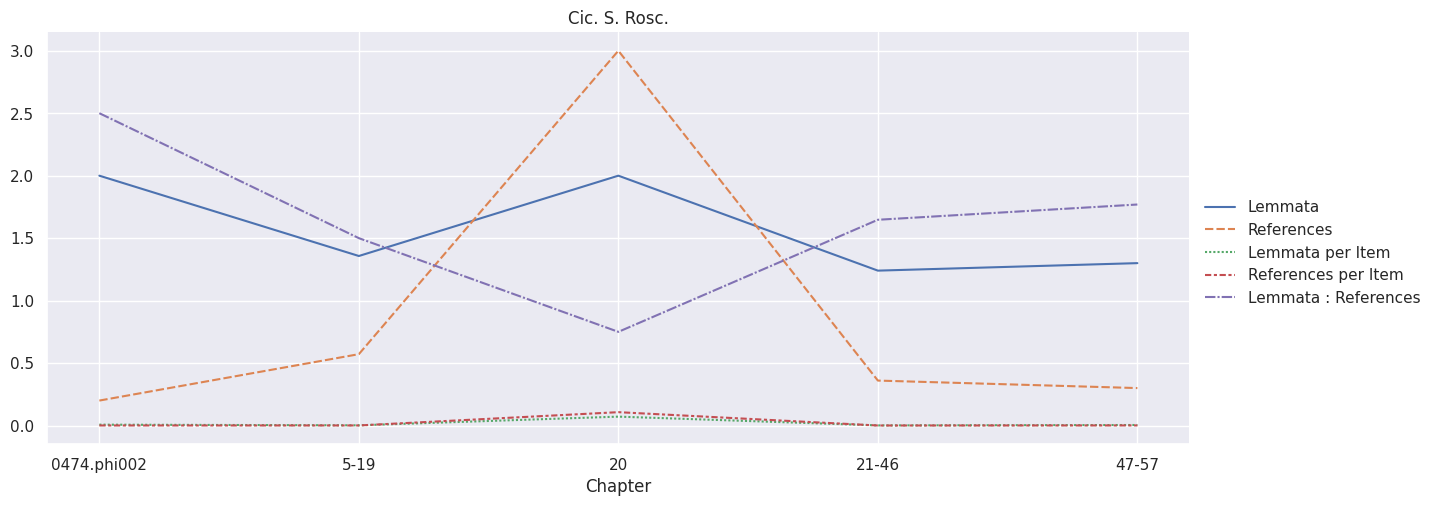

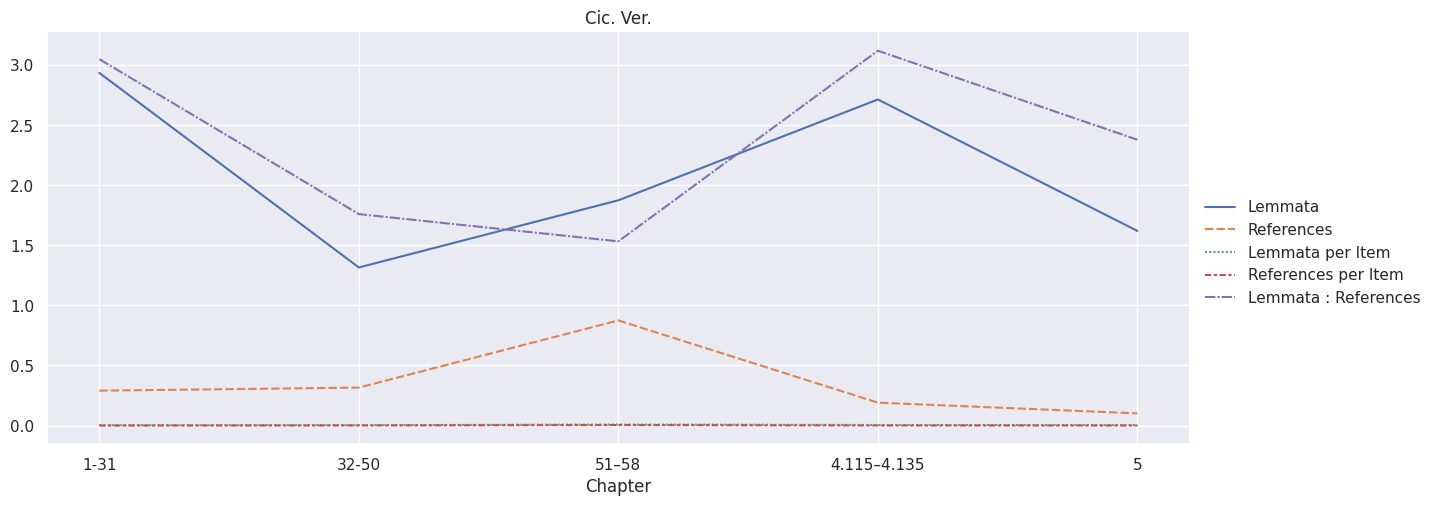

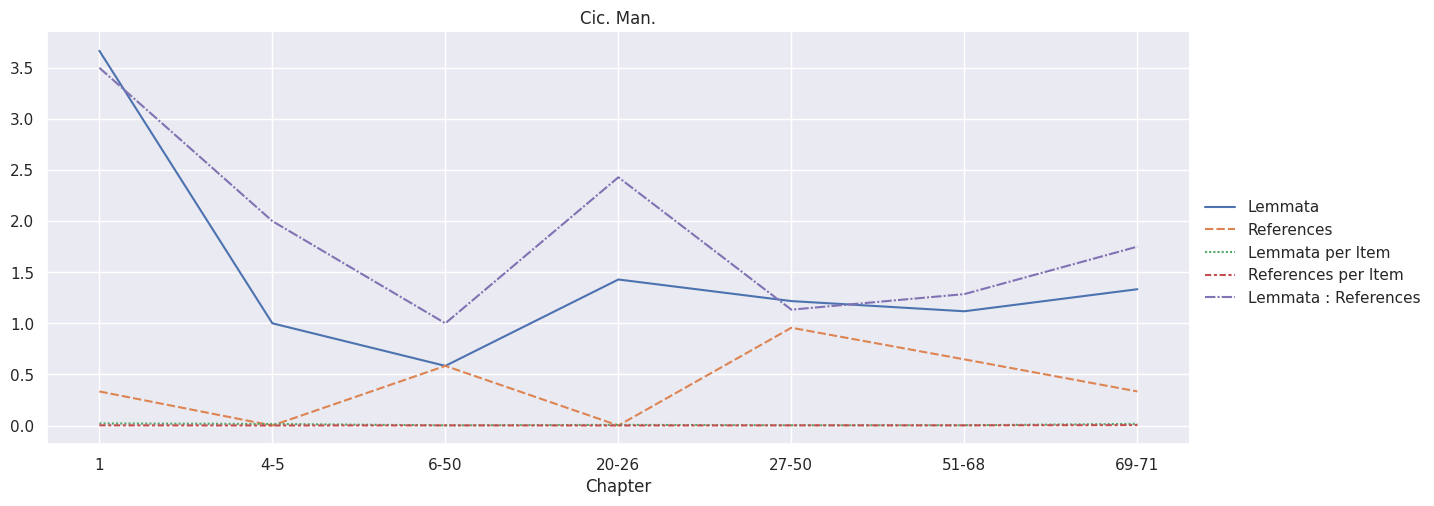

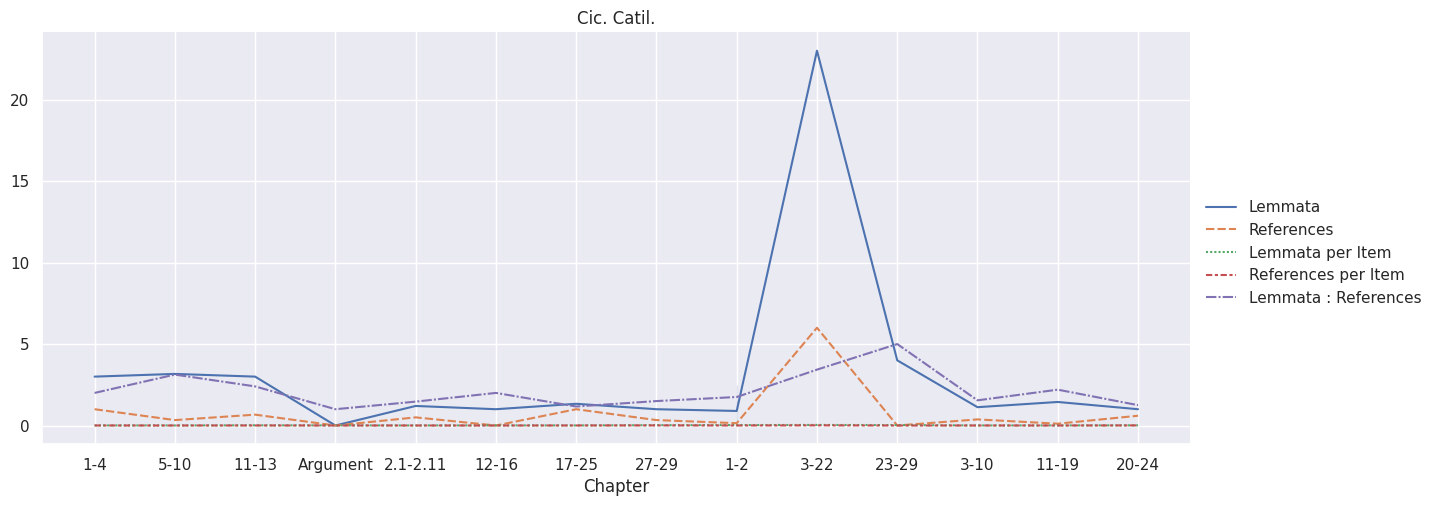

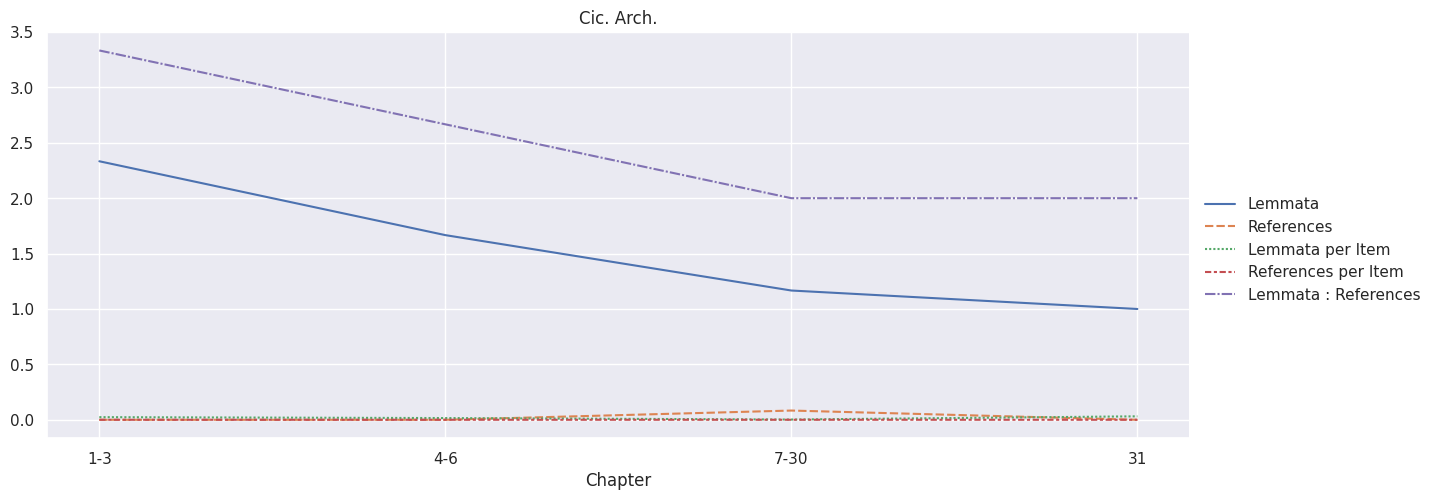

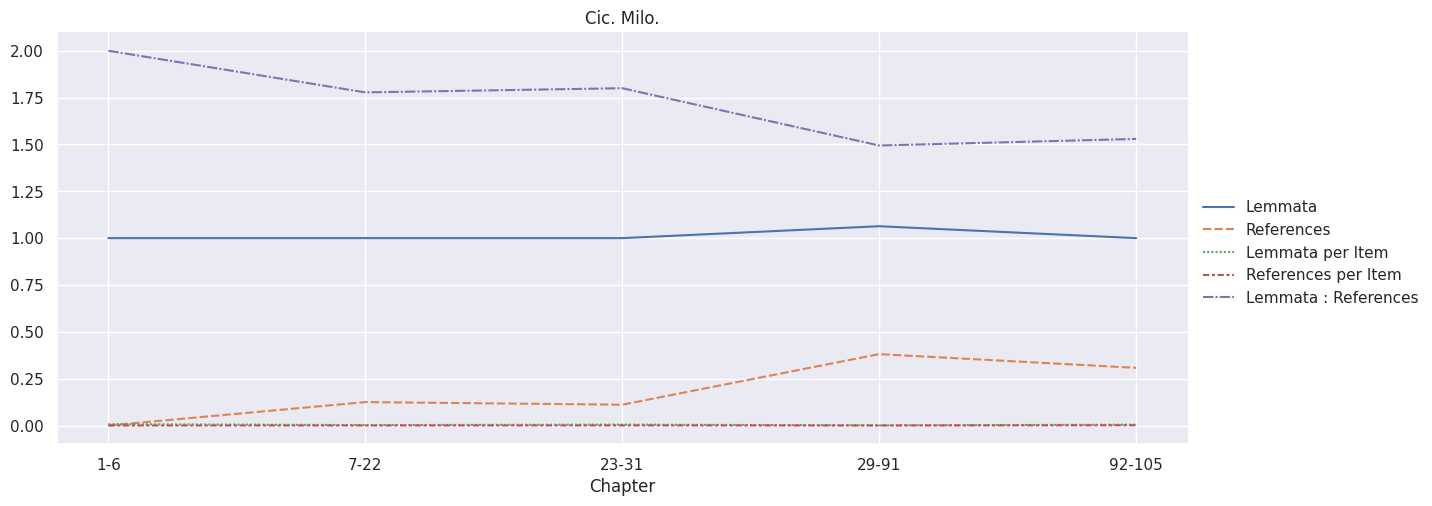

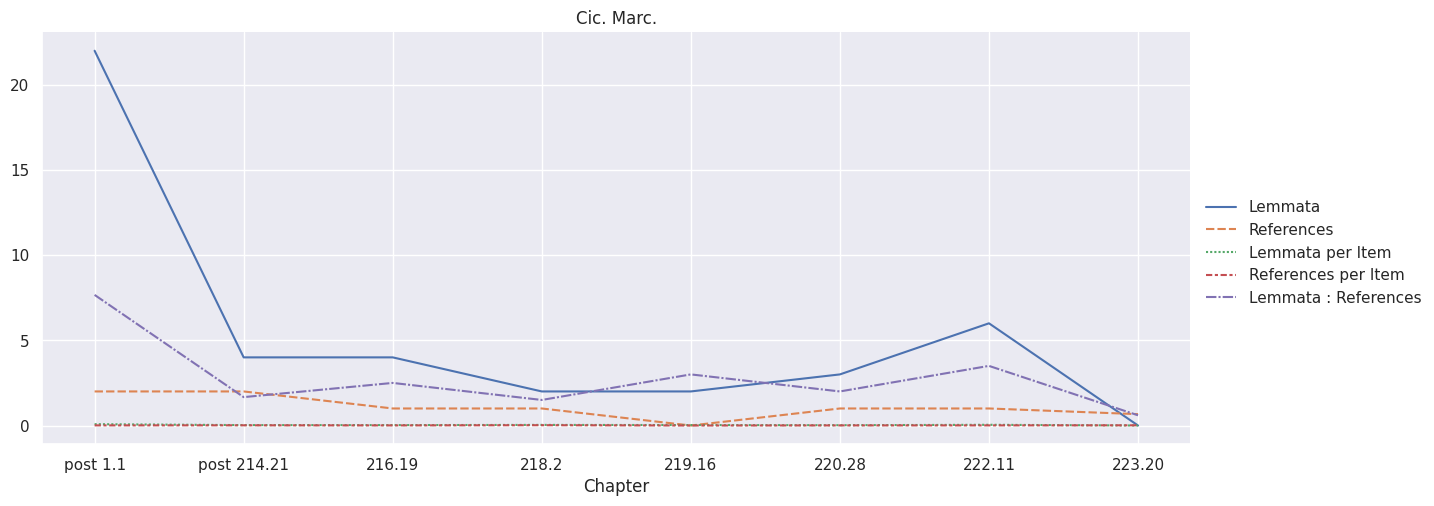

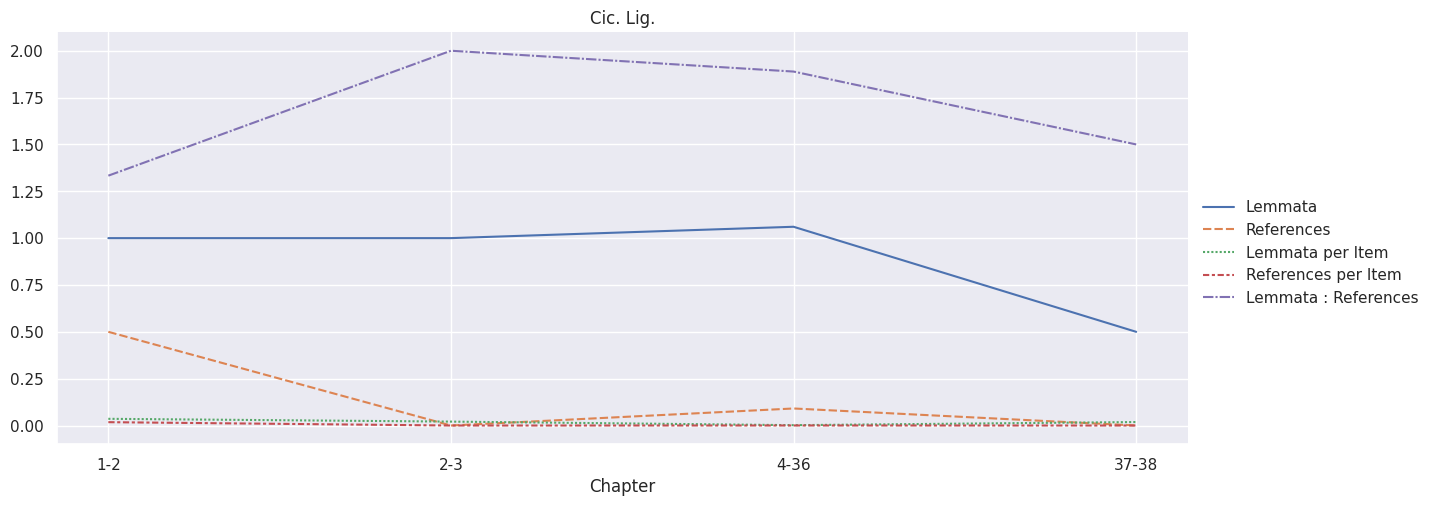

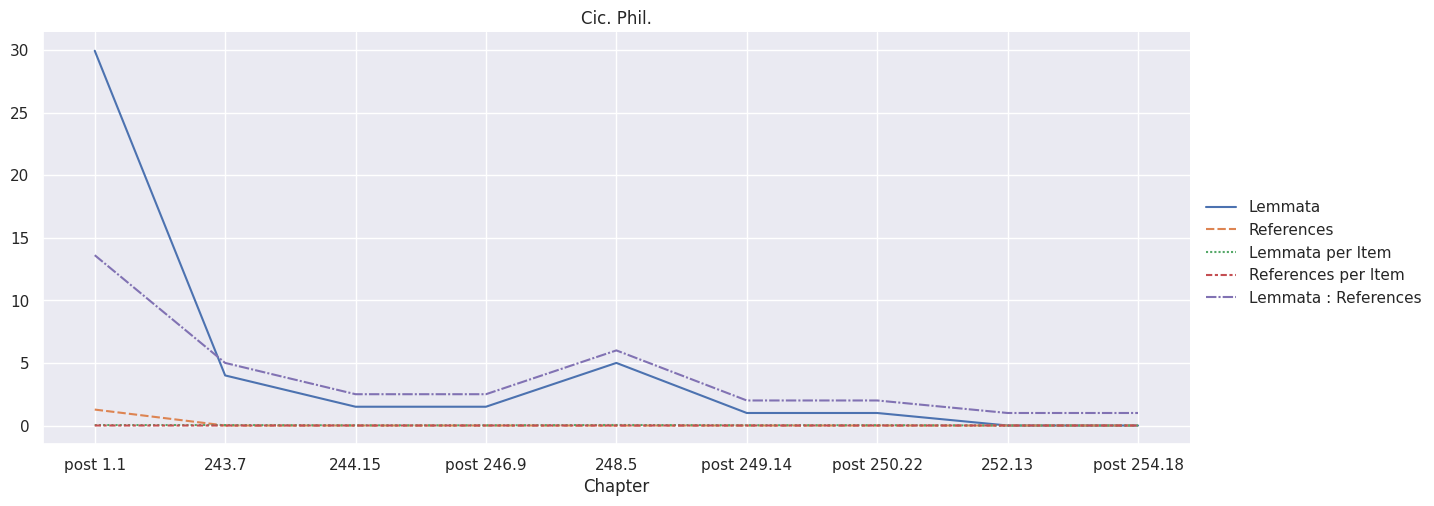

In [27]:
import matplotlib.pyplot as plt
cicero_list = ['Cic. S. Rosc.', 'Cic. Ver.', 'Cic. Man.', 'Cic. Catil.', 'Cic. Arch.', 'Cic. Milo.', 'Cic. Marc.', 'Cic. Lig.','Cic. Phil.']
normalizations =[[5,14,1,25,10],[31,19,8,21,19.75], [3,2,24,7,23,17,3],[4,6,3,1,10,5,9,3,1,2,1,2,20,7,8,9,5],[3,3,24,1],
                 [6,16,9,63,13],[1.5, 2,2,1,1,2,1,1.5], [2,2,33,2],[1.57, 1, 2, 2, 1, 1, 2, 2, 1.57]] 
work_counter = 0
for book in textparts: # first three books
    section_elements_count, section_elements_lemmata, section_elements_refs, urns  = [], [], [], []
    
    for chapter in book[1:]:
        label = []
        if chapter[0].get('corresp') is not None:
            label.append(chapter[0].get('corresp'))
        elif chapter[0].get('n') is not None:
            label.append(chapter[0].get('n'))
        else:
            label.append('REPLACE')
        
        count, lemmata, refs = comm_wiz.count_section_elements(chapter)
        section_elements_count.append(sum(count))
        section_elements_lemmata.append(sum(lemmata))
        section_elements_refs.append(sum(refs))
        urns.append(label[-1]) 

    if len(urns) == 1:
        section_elements_count, section_elements_lemmata, section_elements_refs, urns  = [], [], [], []
        for chapter in book[1:][0]:
            label = []
            if chapter[0].get('corresp') is not None:
                label.append(chapter[0].get('corresp'))
            elif chapter[0].get('n') is not None:
                label.append(chapter[0].get('n'))
            else:
                label.append('REPLACE')
            
            count, lemmata, refs = comm_wiz.count_section_elements(chapter)
            section_elements_count.append(sum(count))
            section_elements_lemmata.append(sum(lemmata))
            section_elements_refs.append(sum(refs))
            urns.append(label[-1])   

    start = '1.1'
    for n in range(len(urns)):
        if "urn" in urns[n]:
            tmp = urns[n][-11:]
            if ':' in tmp:
                urns[n] = tmp[tmp.index(':')+1:]
            else:
                urns[n] = tmp
        if urns[n] != 'REPLACE':
            start = urns[n]
        else:
            urns[n] = "post "+start

    if urns[0] == 'post 1.1':
        counter = 0
        new_section_elements_count, new_section_elements_lemmata, new_section_elements_refs, new_urns  = [], [], [], []
        current_ns, current_section_elements_count, current_section_elements_lemmata, current_section_elements_refs = [urns[0]], [], [], []
        for chunk in range(len(urns)):
            if counter == 5:
                new_urns.extend(current_ns)
                new_section_elements_count.append(sum([i for i in current_section_elements_count]))
                new_section_elements_lemmata.append(sum([i for i in current_section_elements_lemmata]))
                new_section_elements_refs.append(sum([i for i in current_section_elements_refs]))
                # append and restart
                current_ns = [urns[chunk]]
                current_section_elements_refs, current_section_elements_count, current_section_elements_lemmata = [], [], []
                counter = 0
        
            current_section_elements_refs.append(section_elements_refs[chunk])
            current_section_elements_count.append(section_elements_count[chunk])
            current_section_elements_lemmata.append(section_elements_lemmata[chunk])
            counter += 1

        new_urns.extend(current_ns)
        new_section_elements_count.append(sum([i for i in current_section_elements_count]))
        new_section_elements_lemmata.append(sum([i for i in current_section_elements_lemmata]))
        new_section_elements_refs.append(sum([i for i in current_section_elements_refs]))

        section_elements_count, section_elements_lemmata, section_elements_refs, urns  = new_section_elements_count, new_section_elements_lemmata, new_section_elements_refs, new_urns    

    print(section_elements_count)
    normalization = pd.Series(normalizations[work_counter], index=urns)
    count_col = pd.Series(section_elements_count, index=urns)
    lemmata_col = pd.Series(section_elements_lemmata, index=urns)
    refs_col = pd.Series(section_elements_refs, index=urns)
    text_info = pd.DataFrame({'count':count_col, 'normalization':normalization, 'Lemmata':lemmata_col, 'References':refs_col })
    text_info['Lemmata'] = text_info['Lemmata'] / text_info['normalization']
    text_info['References'] = text_info['References'] / text_info['normalization']
    text_info['Lemmata per Item'] = text_info['Lemmata'] / text_info['count'] 
    text_info['References per Item'] = text_info['References'] / text_info['count']
    text_info['Lemmata : References'] = (text_info['Lemmata']+1) / (text_info['References']+1)

    #seaboo.relplot(data=text_info, kind="line")
    g = seaboo.relplot(data=text_info.loc[:, 'Lemmata':'Lemmata : References'], kind="line", aspect=2.5)
    g.set(title=cicero_list[work_counter], xlabel="Chapter")
    work_counter +=1


## Heat Mapping AG Latin Grammar References

Work
Cic. Arch.       424.375000
Cic. Catil.      461.728814
Cic. Lig.        475.642857
Cic. Man.        489.421053
Cic. Marc.       415.846154
Cic. Milo.       472.189189
Cic. Phil.       481.500000
Cic. S. Rosc.    440.942857
Cic. Ver.        503.280000
Name: Grammar references, dtype: float64

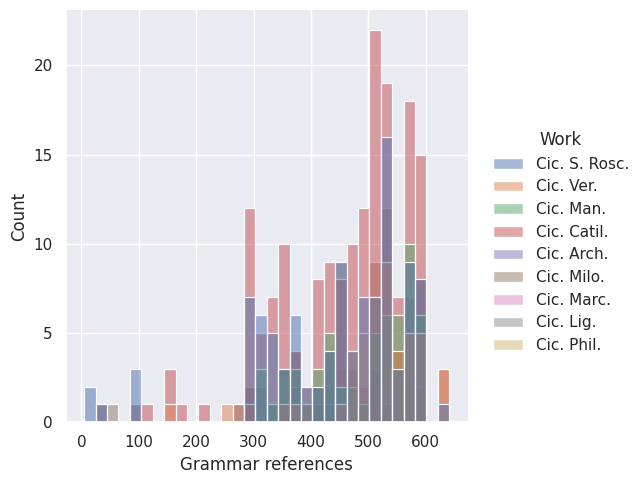

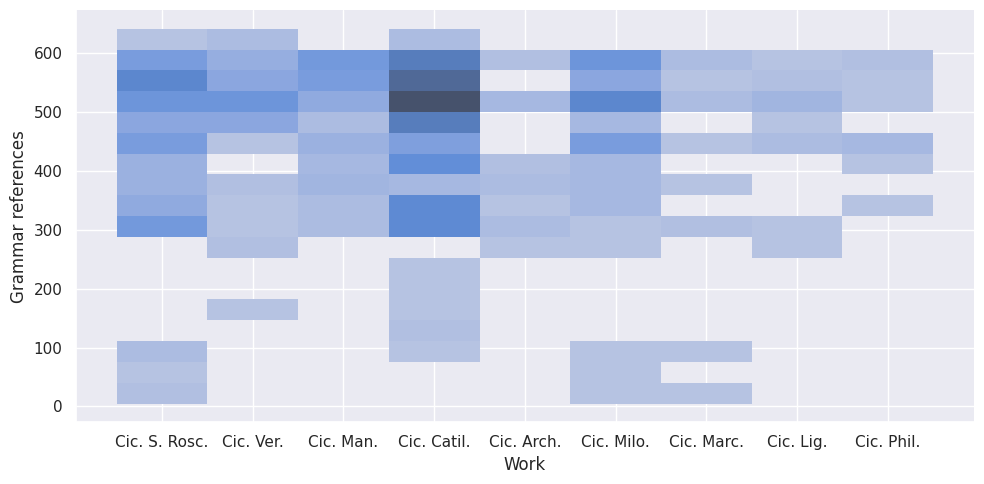

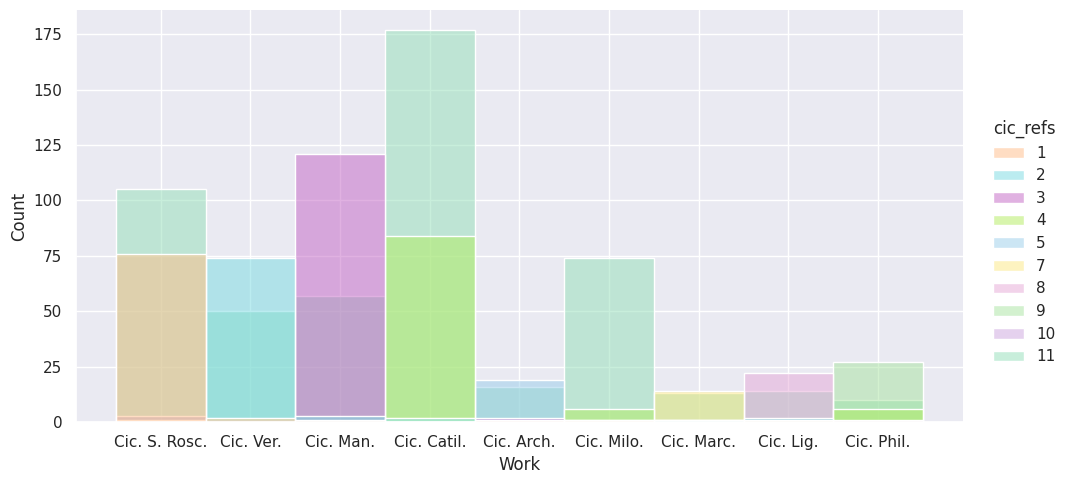

In [ ]:
edges = []
cic_df = pd.DataFrame()
reference_df = pd.DataFrame()
cicero_list = ['','Cic. S. Rosc.', 'Cic. Ver.', 'Cic. Man.', 'Cic. Catil.', 'Cic. Arch.', 'Cic. Milo.', 'Cic. Marc.', 'Cic. Lig.','Cic. Phil.']
doc_counter = 1

for d in docs:
    bibl_list = [urny.values()[0] for urny in d.findall(".//{http://www.tei-c.org/ns/1.0}bibl") if len(urny.values()) > 0]
    #print(milestones[doc_counter-1]) # do this, do milestones
    cic_refs, grammar_refs = comm_wiz.coarse_cicero_cleaner(bibl_list)
    edges.append(cic_refs)

    cic_col = pd.Series(cic_refs)
    count_col = pd.Series(grammar_refs)

    cic_ref_df = pd.DataFrame({'cic_refs': cic_col})
    grammar_ref_df = pd.DataFrame({'Grammar references':count_col})
    
    cic_ref_df['Work'] = cicero_list[doc_counter]
    grammar_ref_df['Work'] = cicero_list[doc_counter]
    
    cic_df = pd.concat([cic_df, cic_ref_df])
    reference_df = pd.concat([reference_df, grammar_ref_df])

    doc_counter += 1



seaboo.set_theme(style="darkgrid")
seaboo.displot(
    data=reference_df, x="Grammar references", hue="Work",
    binwidth=20
)

seaboo.displot(
    data=reference_df, kind='hist', y="Grammar references", x="Work", aspect=2
)

# uncomment to see something interesting
#seaboo.boxplot(data=reference_df, y="grammar_refs", x="work")

my_palette = seaboo.crayon_palette(["Macaroni and Cheese", "Aquamarine", "Fuchsia", "Inchworm", "Cornflower", "Yellow", "Orchid", "Granny Smith Apple","Wisteria", "Sea Green"])
seaboo.displot(
    data=cic_df, hue="cic_refs", x="Work", palette=my_palette, aspect=2
)

# plot mean and range in a scatter plot
ref_means = reference_df.groupby(by='Work').mean()['Grammar references']
ref_ranges = reference_df.groupby(by='Work').mean()['Grammar references']
#seaboo.relplot(data=text_info.loc[:, 'lemmata':'refs_ratio'], kind="line")

## and now... reference graph

['#630077', '#880077', '#040077', '#010077', '#600077', '#410077', '#030077', '#030077', '#010077', '#9d0077', '#4a0077', '#040077', '#010077', '#6d0077', '#e60077', '#030077', '#030077', '#010077', '#190077', '#150077', '#030077', '#010077', '#010077', '#010077', '#600077', '#010077', '#080077', '#010077', '#010077', '#120077', '#110077', '#010077', '#010077', '#010077', '#1d0077', '#030077', '#120077', '#010077', '#230077', '#0d0077', '#080077', '#010077'] [76, 105, 3, 1, 74, 50, 2, 2, 1, 121, 57, 3, 1, 84, 177, 2, 2, 1, 19, 16, 2, 1, 1, 1, 74, 1, 6, 1, 1, 14, 13, 1, 1, 1, 22, 2, 14, 1, 27, 10, 6, 1]


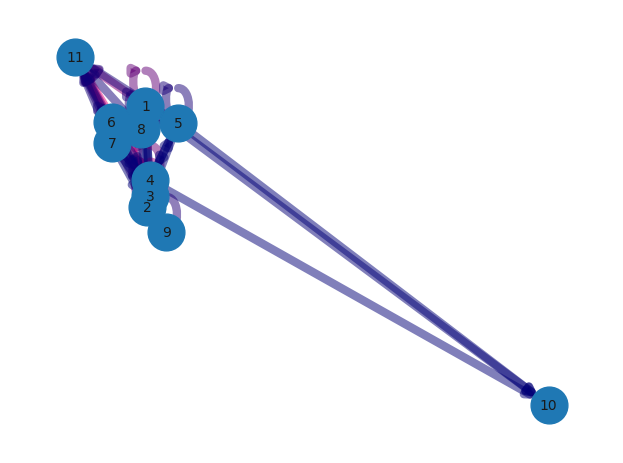

In [25]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import Counter

G = nx.DiGraph()
G.add_nodes_from(range(10))

# cold to hot, ['#RRGGBB']
def color_from_weights(weight_list):
    color_list = []
    for w in weight_list:
        red = hex(round(w*1.3))[2:]
        if len(red) == 1:
            red = "0"+red
        hue = "#"+red+"0077"
        color_list.append(hue)
    return color_list

width_list = []

for i in range(1,10):
    c = Counter(edges[i-1])
    for value in c:
        G.add_edge(i, value, weight=c[value])
        width_list.append(c[value]) #/10)
    #for value in edges[i-1]:
        #G.add_edge(i, value) 

my_colors = color_from_weights(width_list)

#nx.write_edgelist(G, path="grid.edgelist", delimiter=":")
# read edgelist from grid.edgelist
#H = nx.read_edgelist(path="grid.edgelist", delimiter=":")

#pos = nx.spring_layout(H, seed=200)
#nx.draw(H, pos)
#plt.show()

# * * *
G.remove_node(0)

elarge = [(u, v) for (u, v, d) in G.edges(data=True) if d["weight"] > 0.5]
esmall = [(u, v) for (u, v, d) in G.edges(data=True) if d["weight"] <= 0.5]

pos = nx.spring_layout(G)  # positions for all nodes - seed for reproducibility
#pos=nx.kamada_kawai_layout(G)
# nodes
nx.draw_networkx_nodes(G, pos, node_size=700)
print(my_colors, width_list)
# edges
nx.draw_networkx_edges(G, pos, edgelist=G.edges(), width=6, alpha=0.5, edge_color=my_colors, arrows=True) # how do i make this actually rely on the weight thooo
#nx.draw_networkx_edges(G, pos, edgelist=G.edges(), width=6, alpha=0.5, edge_color="b", style="dashed")

# node labels
nx.draw_networkx_labels(G, pos, font_size=10, font_family="sans-serif")
# edge weight labels
edge_labels = nx.get_edge_attributes(G, "weight")
#nx.draw_networkx_edge_labels(G, pos, edge_labels)

ax = plt.gca()
ax.margins(0.08)
plt.axis("off")
plt.tight_layout()
plt.show()

## Bipartite Cicero to AG Latin Grammar Mapping

In [ ]:
# one step at a time. first, get the most basic form of this going
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite

def connect_refs(textparts_slice, ref_edge_color, comm_bin_size = 30, working_title=""):
    source_edges = []
    grammar_edges = []
    grammar_ref_set = set()
    my_ns = []
    source_ns = []

    # textparts is a 3D list 
    for book in textparts_slice: # first three books
        #print(type(book), book)
        for chapter in book:
            grammar_by_chapter = []
            source_by_chapter = []
            # binning tbd
            label = []
            if len(chapter):
                # grab n here
                if chapter[0].get('n') is not None and '.' in chapter[0].get('n'):
                    label.append(chapter[0].get('n'))
                else:
                    label.append('REPLACE')
                for section in chapter:
                    # leading chapter textpart may give you your node label for edge 0  
                    bibl_list = [urny.values()[0] for urny in section.findall(".//{http://www.tei-c.org/ns/1.0}bibl") if len(urny.values()) > 0]
                    cic_refs, grammar_refs = comm_wiz.coarse_cicero_cleaner(bibl_list, really_coarse=True)
                    if len(cic_refs) > 0:
                        source_by_chapter.extend(cic_refs)
                    if len(grammar_refs) > 0:
                        grammar_by_chapter.extend(grammar_refs)
                        grammar_ref_set = grammar_ref_set.union(set(grammar_refs))
            else:
                # grab n here
                if chapter.get('n') is not None and '.' in chapter.get('n'):
                    label.append(chapter[0].get('n'))
                else:
                    label.append('REPLACE')
                bibl_list = [urny.values()[0] for urny in chapter.findall(".//{http://www.tei-c.org/ns/1.0}bibl") if len(urny.values()) > 0]
                cic_refs, grammar_refs = comm_wiz.coarse_cicero_cleaner(bibl_list, really_coarse=True)
                if len(cic_refs) > 0:
                    source_by_chapter.extend(cic_refs)
                if len(grammar_refs) > 0:
                    grammar_by_chapter.extend(grammar_refs)
                    grammar_ref_set = grammar_ref_set.union(set(grammar_refs))
            if len(grammar_by_chapter) > 0:
                grammar_edges.append(grammar_by_chapter)
                my_ns.append(label[-1])
            if len(source_by_chapter) > 0:
                source_edges.append(source_by_chapter)
                source_ns.append(label[-1])

    start = '1.1'
    for blah in [my_ns, source_ns]:
        for n in range(len(blah)):
            if "." in blah[n]:
                start = blah[n]
            else:
                blah[n] = "post "+start

    counter = 0
    new_ns, new_grammar_edges = [], []
    current_ns, current_grammar_edges = [my_ns[0]], []
    for chunk in range(len(my_ns)):
        if counter == comm_bin_size:
            new_ns.extend(current_ns)
            new_grammar_edges.append(current_grammar_edges)
            # append and restart
            current_ns = [my_ns[chunk]]
            current_grammar_edges = []
            counter = 0
        
        current_grammar_edges.extend(grammar_edges[chunk])
        counter += 1

    new_ns.extend(current_ns)
    new_grammar_edges.append(current_grammar_edges)
    
    #print(source_edges)
    #print(grammar_ref_set)

    grammar_ref_set_sorted = list(grammar_ref_set)
    grammar_ref_set_sorted.sort()

    B = nx.Graph()
    B.add_nodes_from(new_ns, bipartite=0)
    B.add_nodes_from(grammar_ref_set_sorted, bipartite=1)

    edge_list = comm_wiz.bipartite_edges_from_2d_references(new_grammar_edges, new_ns)

    B.add_weighted_edges_from(edge_list)

    top_nodes, bottom_nodes = bipartite.sets(B)
    top_list = list(top_nodes)
    top_list.sort()
    pos = nx.bipartite_layout(B, new_ns)

    nx.draw_networkx_nodes(B, pos,node_color="#DAAADD", node_size=85)
    for (src, dest, data) in B.edges(data=True):
        nx.draw_networkx_edges(B, pos, edgelist=[(src, dest)], width=0.5*data['weight'],edge_color=ref_edge_color, alpha=0.5) # how do i make this actually rely on the weight thooo
    #nx.draw_networkx_edges(G, pos, edgelist=G.edges(), width=6, alpha=0.5, edge_color="b", style="dashed")

    # node labels
    nx.draw_networkx_labels(B, pos, font_size=10, font_family="sans-serif")
    # edge weight labels
    #nx.draw_networkx_edge_labels(B, pos, font_size=8)
    ax = plt.gca()
    ax.set(title=working_title)
    plt.tight_layout()
    #plt.autoscale(enable=True, axis='both', tight=None)
    plt.show()

cicero_list = ['Cic. S. Rosc.', 'Cic. Ver.', 'Cic. Man.', 'Cic. Catil.', 'Cic. Arch.', 'Cic. Milo.', 'Cic. Marc.', 'Cic. Lig.','Cic. Phil.']
bin_list = [4,4,3,7,1,5,2,1,1]
for i in range(len(textparts)):
    # do this for cic refs as well
    connect_refs(textparts[i],"#AACC"+str(9-i)+"F",bin_list[i],cicero_list[i])


## Bipartite Cicero to References by Category

In [ ]:
# one step at a time. first, get the most basic form of this going
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms import bipartite

def connect_refs(textparts_slice, ref_edge_color, comm_bin_size = 30, working_title=""):
    source_edges = []
    source_ns = []

    # textparts is a 3D list 
    for book in textparts_slice: # first three books
        #print(type(book), book)
        for chapter in book:
            source_by_chapter = []
            # binning tbd
            label = []
            if len(chapter):
                # grab n here
                if chapter[0].get('n') is not None and '.' in chapter[0].get('n'):
                    label.append(chapter[0].get('n'))
                else:
                    label.append('REPLACE')
                for section in chapter:
                    # leading chapter textpart may give you your node label for edge 0  
                    bibl_list = [urny.values()[0] for urny in section.findall(".//{http://www.tei-c.org/ns/1.0}bibl") if len(urny.values()) > 0]
                    cic_refs, grammar_refs = comm_wiz.coarse_cicero_cleaner(bibl_list, really_coarse=True)
                    if len(cic_refs) > 0:
                        cic_refs = comm_wiz.describe_cicero_labels(cic_refs)
                        source_by_chapter.extend(cic_refs)
            else:
                # grab n here
                if chapter.get('n') is not None and '.' in chapter.get('n'):
                    label.append(chapter[0].get('n'))
                else:
                    label.append('REPLACE')
                bibl_list = [urny.values()[0] for urny in chapter.findall(".//{http://www.tei-c.org/ns/1.0}bibl") if len(urny.values()) > 0]
                cic_refs, grammar_refs = comm_wiz.coarse_cicero_cleaner(bibl_list, really_coarse=True)
                if len(cic_refs) > 0:
                    cic_refs = comm_wiz.describe_cicero_labels(cic_refs)
                    source_by_chapter.extend(cic_refs)
            if len(source_by_chapter) > 0:
                source_edges.append(source_by_chapter)
                source_ns.append(label[-1])

    start = '1.1'
    for n in range(len(source_ns)):
        if "." in source_ns[n]:
            start = source_ns[n]
        else:
            source_ns[n] = "post "+start

    counter = 0
    new_ns, new_grammar_edges = [], []
    current_ns, current_grammar_edges = [source_ns[0]], []
    for chunk in range(len(source_ns)):
        if counter == comm_bin_size:
            new_ns.extend(current_ns)
            new_grammar_edges.append(current_grammar_edges)
            # append and restart
            current_ns = [source_ns[chunk]]
            current_grammar_edges = []
            counter = 0
        
        current_grammar_edges.extend(source_edges[chunk])
        counter += 1

    new_ns.extend(current_ns)
    new_grammar_edges.append(current_grammar_edges)
    
    if comm_bin_size < 1:
        new_ns, new_grammar_edges = source_ns, source_edges

    #print(source_edges)
    #print(grammar_ref_set)

    # play with doing this in such a way that you exclude the leading Argument
    edge_list = comm_wiz.bipartite_edges_from_2d_references(new_grammar_edges, new_ns)
    source_set = set([i[1] for i in edge_list])
    source_list = list(source_set)
    source_list.sort() 

    refs = nx.Graph()
    refs.add_nodes_from(new_ns, bipartite=0)
    refs.add_nodes_from(source_list, bipartite=1)

    refs.add_weighted_edges_from(edge_list)
   
    #print(refs.nodes, refs.edges)

    top_nodes, bottom_nodes = bipartite.sets(refs)
    top_list = list(top_nodes)
    top_list.sort()
    pos = nx.bipartite_layout(refs, new_ns)

    nx.draw_networkx_nodes(refs, pos,node_color="#DAAADD",node_size=85)
    # edges
    for (src, dest, data) in refs.edges(data=True):
        nx.draw_networkx_edges(refs, pos, edgelist=[(src, dest)], width=0.5*data['weight'],edge_color=ref_edge_color, alpha=0.5) # how do i make this actually rely on the weight thooo
    #nx.draw_networkx_edges(G, pos, edgelist=G.edges(), width=6, alpha=0.5, edge_color="b", style="dashed")

    # node labels
    nx.draw_networkx_labels(refs, pos, font_size=8, font_family="sans-serif")
    # edge weight labels
    #nx.draw_networkx_edge_labels(refs, pos, font_size=8) #, edge_labels)
    ax = plt.gca()
    ax.set(title=working_title)
    plt.tight_layout()
    #plt.autoscale(enable=True, axis='both', tight=None)
    plt.show()

cicero_list = ['Cic. S. Rosc.', 'Cic. Ver.', 'Cic. Man.', 'Cic. Catil.', 'Cic. Arch.', 'Cic. Milo.', 'Cic. Marc.', 'Cic. Lig.','Cic. Phil.']
bin_list = [4,5,5,8,2,5,2,3,2] # try 3 for milo if this keeps wiggin' out
for i in range(len(textparts)):
    # do this for cic refs as well
    connect_refs(textparts[i],"#AACC"+str(9-i)+"F",bin_list[i],cicero_list[i])
